# Step 3 · Exploratory Data Analysis (EDA)

**Input:** `data/processed/wq_curated.parquet` from Step 2. Only **analysis-ready** rows are used: single readings in standard units, with no QC, rejected, duplicate, censored, impossible or suspect values.
**Goal:** understand the water-quality data *before* building the warehouse and models, and give first, evidence-based answers to the **mandatory business questions Q1–Q8**.

| Brief requirement (§5) | Section |
|---|---|
| A. Numerical analysis (mean, median, min, max, variance, std, quartiles, IQR, skewness, kurtosis, histograms, box plots) | 1 |
| B. Categorical analysis (frequency, % contribution, rare categories, cross-tabs with outcomes) | 2 |
| C. Temporal analysis (yearly, quarterly, monthly, weekly, day-of-week, time band, peak/low periods) | 3 |
| D. Geographic / entity analysis (regions, states, sites, organizations, map) | 4 |
| E. Outcome analysis (**counts vs rates**, no causal claims) | 5 |
| Q5: relationships among pH, DO, turbidity, nutrients (co-located data) | 6 |
| Answers to Q1–Q8 | 7 |

Every chart has *why this chart* and an **🔎 Inference** written from the actual output.
**Reading rule:** a *count* says how much was measured; a *rate* says how often it was bad. High volume is not the same as high risk.

## 0 · Setup
DuckDB reads the curated Parquet file directly; a view `a` holds only analysis-ready rows.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, json
from pathlib import Path
pd.set_option('display.max_rows', 80); pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / 'data' / 'processed' / 'wq_curated.parquet').exists(): ROOT = p; break
CUR = ROOT / 'data' / 'processed' / 'wq_curated.parquet'
OUT = ROOT / '02_eda'; FIG, TAB = OUT / 'figures', OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(); con.execute("SET memory_limit='3GB'")
con.execute(f"CREATE VIEW cur AS SELECT * FROM '{CUR.as_posix()}'")
con.execute("CREATE VIEW a AS SELECT * FROM cur WHERE analysis_ready")
def q(sql): return con.execute(sql).df()
def save_tab(df, name, index=False): df.to_csv(TAB / f'E{name}.csv', index=index); return df
def save_fig(name): plt.tight_layout(); plt.savefig(FIG / f'E{name}.png', dpi=130, bbox_inches='tight'); plt.show()
PARAMS = ['Temperature, water', 'Dissolved oxygen (DO)', 'pH', 'Turbidity', 'Conductivity', 'Nitrate']
SHORT = {'Temperature, water': 'Temperature', 'Dissolved oxygen (DO)': 'Dissolved oxygen', 'pH': 'pH', 'Turbidity': 'Turbidity', 'Conductivity': 'Conductivity', 'Nitrate': 'Nitrate'}
UNIT = {'Temperature, water': '°C', 'Dissolved oxygen (DO)': 'mg/L', 'pH': 'pH', 'Turbidity': 'NTU', 'Conductivity': 'µS/cm', 'Nitrate': 'mg/L as N'}
LOGP = {'Turbidity', 'Conductivity', 'Nitrate'}
ov = q('''SELECT count(*) AS results, count(DISTINCT site) AS sites, count(DISTINCT org) AS organizations, count(DISTINCT state) AS states,
                 min(dt) AS first_date, max(dt) AS last_date, sum(exceedance_flag) AS exceedances, sum(high_risk_flag) AS high_risk FROM a''').T
display(save_tab(ov.rename(columns={0: 'Value'}), '00_overview', index=True))

,Value
results,3772033
sites,49271
organizations,468
states,54
first_date,2024-01-01 00:00:00
last_date,2025-12-31 00:00:00
exceedances,292571.0
high_risk,97752.0


## 1 · Numerical analysis (brief §5A)
**What:** the full set of summary statistics for each parameter, followed by histograms and box plots.
**Why:** this describes the *typical* value, the spread and the shape of each parameter after cleaning. Skewed parameters need medians, not means, and log scales.

,Unit,n,mean,median,min,max,variance,std,q1,q3,skewness,kurtosis,IQR,CV (std/mean)
Parameter,,,,,,,,,,,,,,
Temperature,°C,1912387.0,16.978,17.300,-4.987,49.80,3.845100e+01,6.201,13.21,21.150,-0.248,-0.020,7.940,0.365
Dissolved oxygen,mg/L,690164.0,7.619,8.010,0.000,25.00,1.071100e+01,3.273,6.00,9.820,-0.495,0.179,3.820,0.430
pH,pH,658268.0,7.647,7.764,0.000,13.96,6.140000e-01,0.784,7.22,8.180,-1.112,4.613,0.960,0.102
Turbidity,NTU,336418.0,33.688,4.320,0.000,9733.91,1.053948e+05,324.646,1.53,10.500,16.732,294.089,8.970,9.637
Conductivity,µS/cm,131417.0,2022.361,107.300,0.000,196876.59,8.926684e+07,9448.113,59.90,370.900,6.726,59.805,311.000,4.672
Nitrate,mg/L as N,43379.0,1.752,0.400,0.000,98.80,1.996700e+01,4.468,0.10,1.411,7.650,94.144,1.311,2.550


C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2889201102.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.hist(s, bins=50, color='#4C72B0'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2))
C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2889201102.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.hist(s, bins=50, color='#4C72B0'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2))
C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2889201102.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.hist(s, bins=50, color='#4C72B0'); bx.boxplot(s, vert=False, whi

C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2889201102.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.hist(s, bins=bins, color='#4C72B0'); ax.set_xscale('log'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2)); bx.set_xscale('log')
C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2889201102.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.hist(s, bins=bins, color='#4C72B0'); ax.set_xscale('log'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2)); bx.set_xscale('log')


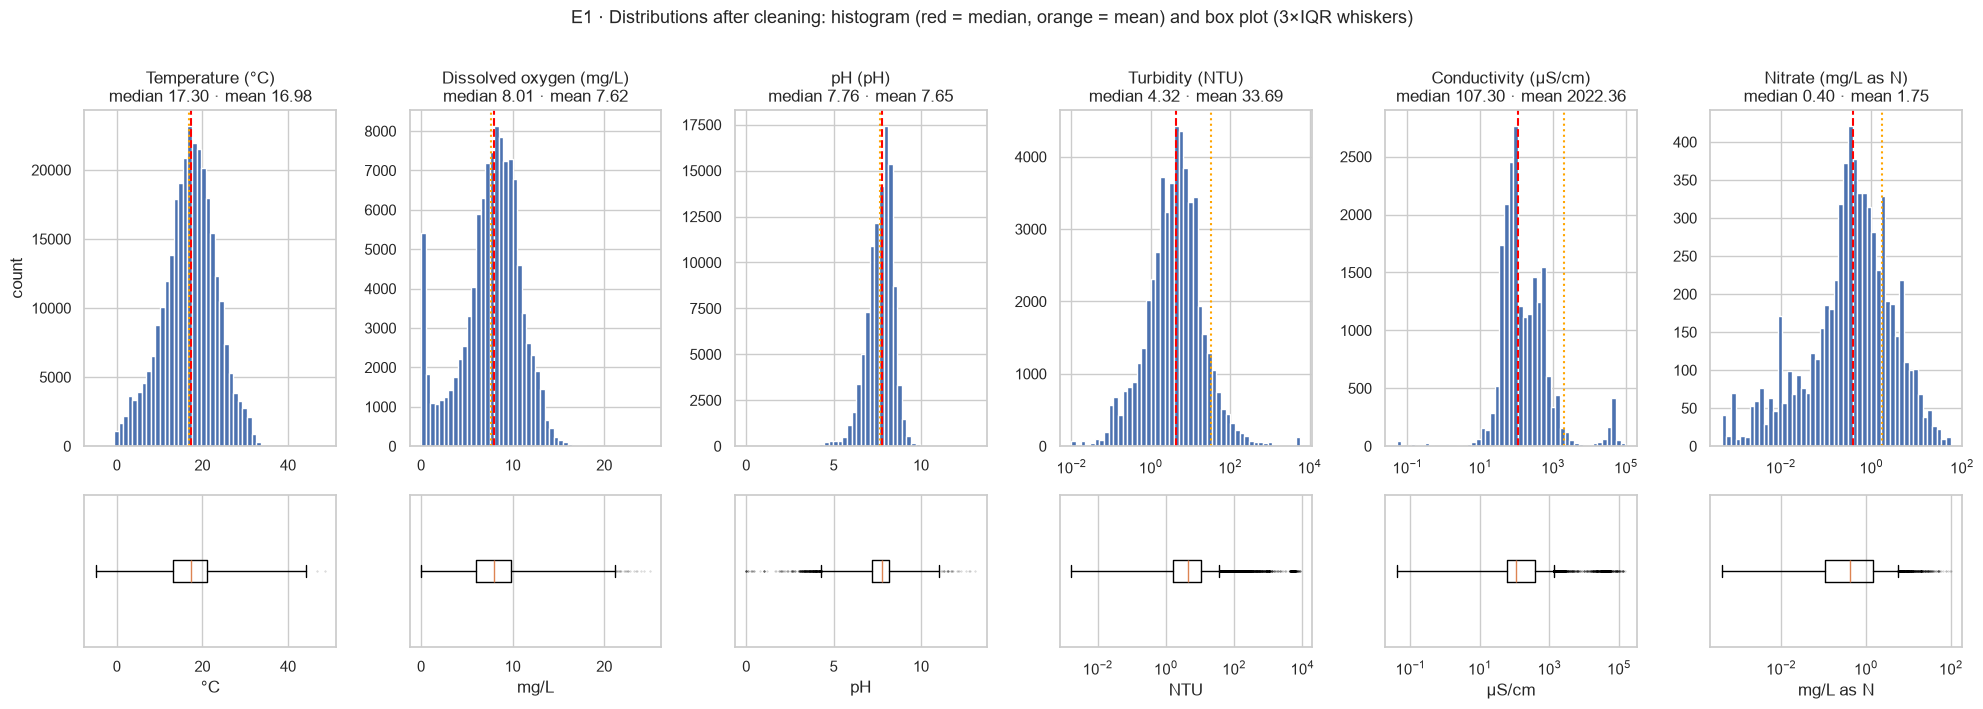

In [2]:
rows = []
for p in PARAMS:
    r = q(f'''SELECT count(*) n, avg(value_std) mean, median(value_std) median, min(value_std) min, max(value_std) max,
                     var_samp(value_std) variance, stddev(value_std) std, quantile_cont(value_std, 0.25) q1, quantile_cont(value_std, 0.75) q3,
                     skewness(value_std) skewness, kurtosis(value_std) kurtosis FROM a WHERE param = '{p}' ''').iloc[0]
    rows.append({'Parameter': SHORT[p], 'Unit': UNIT[p], **r.to_dict()})
num = pd.DataFrame(rows).set_index('Parameter'); num['IQR'] = num.q3 - num.q1
num['CV (std/mean)'] = num['std'] / num['mean']
display(save_tab(num.round(3), '01_numeric_summary', index=True))
samp = q("SELECT param, value_std FROM (SELECT param, value_std FROM a) USING SAMPLE reservoir(600000 ROWS) REPEATABLE (3)")
fig, axes = plt.subplots(2, 6, figsize=(20, 7), gridspec_kw={'height_ratios': [2.2, 1]})
for i, p in enumerate(PARAMS):
    s = samp[samp.param == p].value_std; ax, bx = axes[0, i], axes[1, i]
    if p in LOGP:
        s = s[s > 0]; bins = np.logspace(np.log10(s.quantile(0.001)), np.log10(s.quantile(0.999)), 50)
        ax.hist(s, bins=bins, color='#4C72B0'); ax.set_xscale('log'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2)); bx.set_xscale('log')
    else:
        ax.hist(s, bins=50, color='#4C72B0'); bx.boxplot(s, vert=False, whis=3, flierprops=dict(marker='.', markersize=1, alpha=0.2))
    ax.axvline(num.loc[SHORT[p], 'median'], color='red', ls='--'); ax.axvline(num.loc[SHORT[p], 'mean'], color='orange', ls=':')
    ax.set(title=f"{SHORT[p]} ({UNIT[p]})\nmedian {num.loc[SHORT[p], 'median']:.2f} · mean {num.loc[SHORT[p], 'mean']:.2f}", ylabel='count' if i == 0 else '')
    bx.set(yticks=[], xlabel=UNIT[p])
fig.suptitle('E1 · Distributions after cleaning: histogram (red = median, orange = mean) and box plot (3×IQR whiskers)', y=1.01, fontsize=13)
save_fig('01_distributions')

**Why this chart:** the histogram shows the shape, and the box plot under it shows the median, the middle 50% and the extremes on the same axis. The red median vs orange mean lines make skew visible: the further apart they are, the more lopsided the data.

**🔎 Inference (E1): numerical analysis**
- **Typical (median) values after cleaning:** temperature **17.3 °C**, dissolved oxygen **8.0 mg/L**, pH **7.76**, turbidity **4.3 NTU**, conductivity **107 µS/cm**, nitrate **0.40 mg/L as N**. These describe ordinary fresh surface water: slightly alkaline, well oxygenated, mostly clear, and low in nitrate.
- **Temperature, DO and pH are near-symmetric** (skewness −0.25, −0.50, −1.11), so mean ≈ median and both are fair summaries.
  - pH's negative skew and high kurtosis (4.6) come from a **tail of acidic readings** (down to pH 4–5), for example blackwater streams in the South.
  - DO's IQR (6.0–9.8 mg/L) shows most water is healthy, while its lower tail reaches 0 (hypoxia).
- **Turbidity, conductivity and nitrate are strongly right-skewed** (skewness 16.7, 6.7, 7.7; CV 9.6, 4.7, 2.6):
  - **Turbidity:** mean 33.7 vs median 4.3 NTU.
  - **Conductivity:** mean 2,022 vs median 107 µS/cm, inflated by salty coastal sites.
  - **Nitrate:** mean 1.75 vs median 0.40 mg/L.
  - A small number of very high values (storms, estuaries, farm drainage) pull the mean far above the typical value.
- **Impact:**
  - Dashboards and site comparisons should use **medians and percentiles**.
  - Charts for these three use **log scales**.
  - Regression should consider **log-transforming** turbidity, conductivity and nitrate (Step 10).

## 2 · Categorical analysis (brief §5B)
**What:** frequency and % contribution of the main categories, **rare categories** (< 1% share), and cross-tabulations with the outcome (**exceedance rate**).
**Why:** categories become the warehouse *dimensions* and the model *features*. Rare categories may need grouping, and a cross-tab shows which categories go together with poor water quality.

,Attribute,category,n,exceed_rate,pct
0,Region,Midwest,1864051,4.22,49.42
1,Region,South,1030882,16.44,27.33
2,Region,West,673704,3.50,17.86
3,Region,Northeast,177513,9.08,4.71
4,Region,Unknown,13500,12.33,0.36
5,Region,Territory,12383,24.25,0.33
0,Water type,Not Reported,2905374,5.76,77.02
1,Water type,Surface Water,835113,14.29,22.14
2,Water type,Groundwater,23535,23.71,0.62
3,Water type,Ocean Water,5271,0.42,0.14


Rare categories (< 1% of results):


,Attribute,category,n,exceed_rate,pct
4,Region,Unknown,13500,12.333,0.358
5,Region,Territory,12383,24.251,0.328
2,Water type,Groundwater,23535,23.709,0.624
3,Water type,Ocean Water,5271,0.417,0.140
4,Water type,Wastewater Treatment Plant Effluent,2287,15.348,0.061
5,Water type,Stormwater,368,3.533,0.010
6,Water type,Drinking Water,57,29.825,0.002
7,Water type,Leachate,13,23.077,0.000
8,Water type,Industrial Effluent,9,11.111,0.000
9,Water type,Landfill effluent,6,33.333,0.000


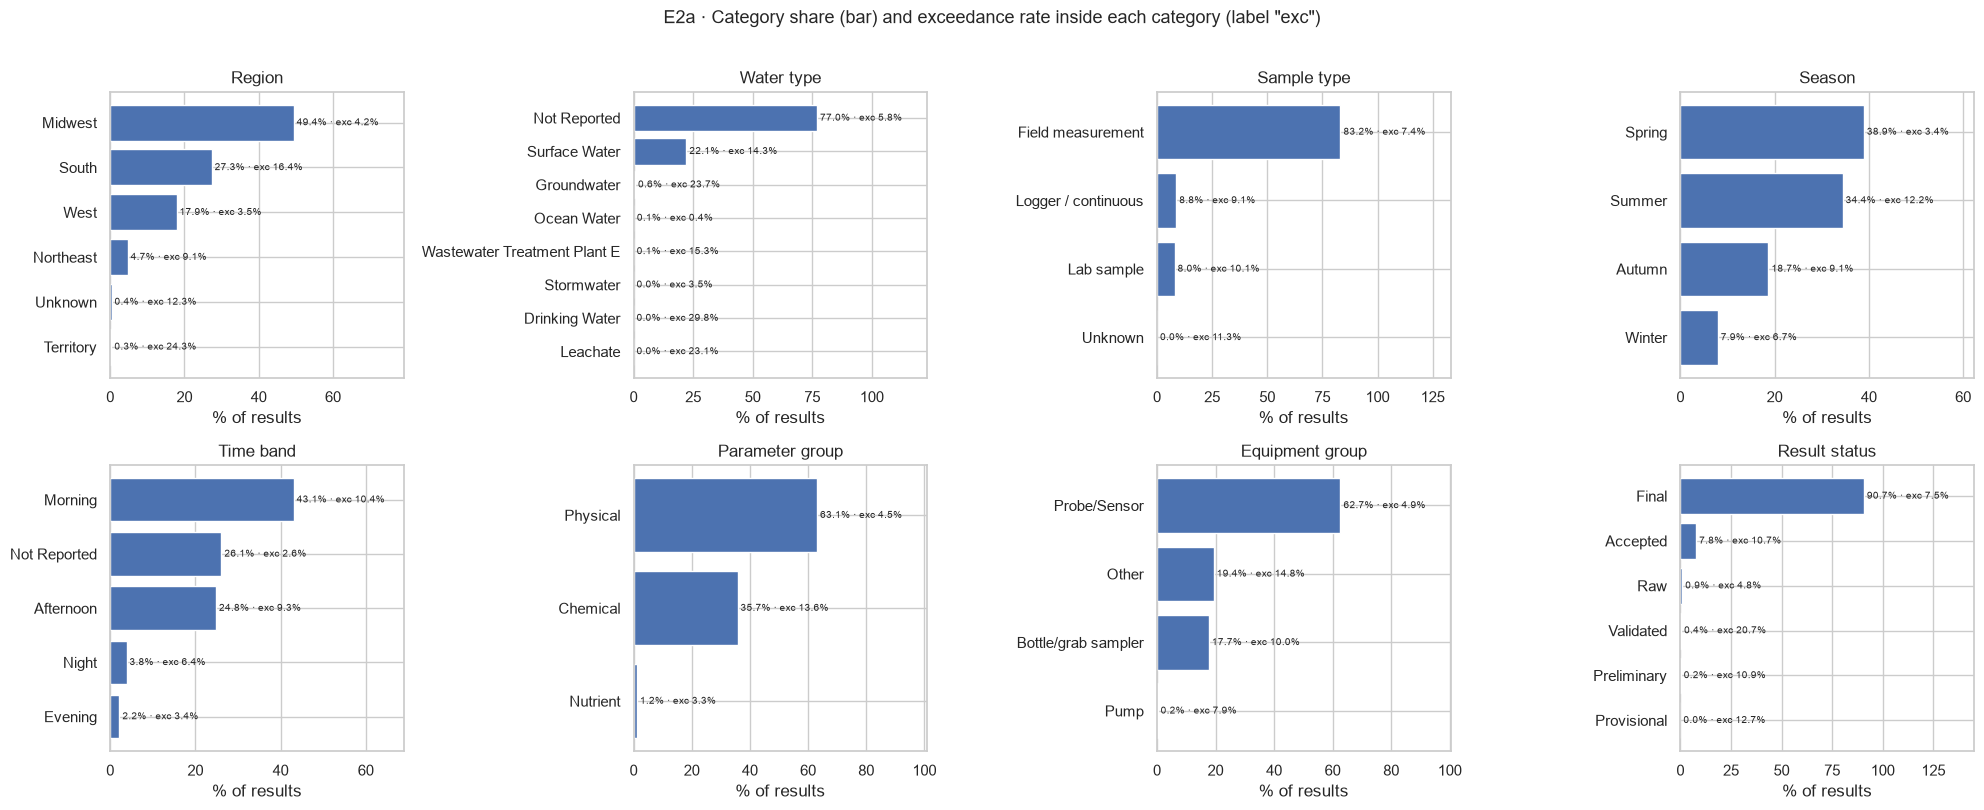

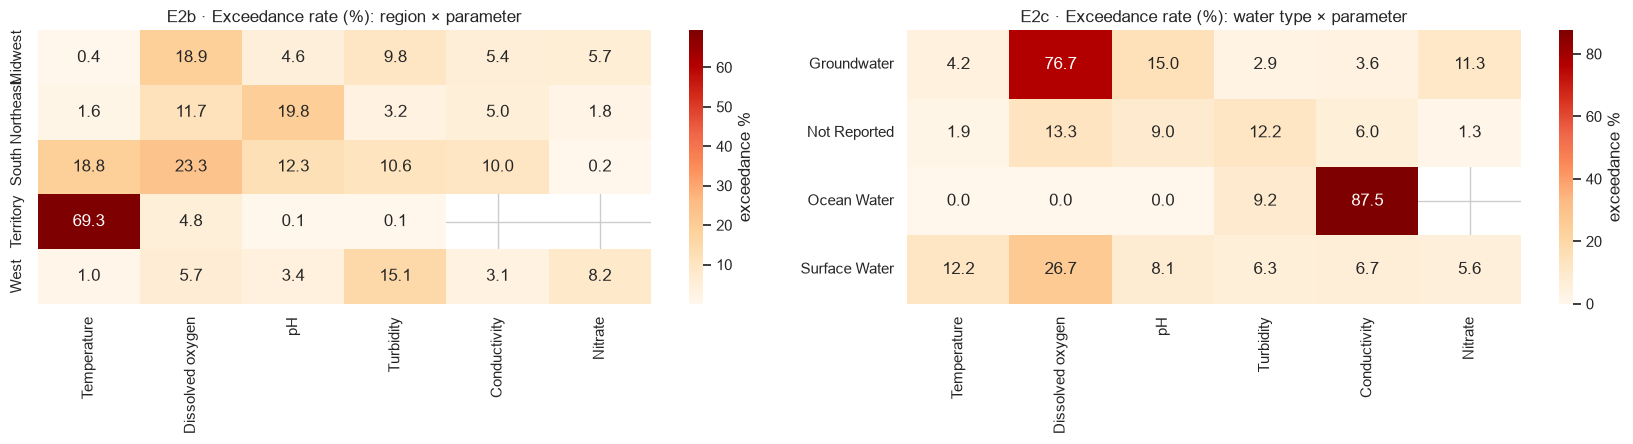

In [3]:
CATS = {'Region': 'region', 'Water type': 'water_type', 'Sample type': 'sample_type_group', 'Season': 'season',
        'Time band': 'time_band', 'Parameter group': 'parameter_group', 'Equipment group': 'equipment_group', 'Result status': 'status'}
freq_all, rare_all = [], []
for name, col in CATS.items():
    d = q(f"SELECT coalesce({col}, '(blank)') AS category, count(*) n, avg(exceedance_flag) * 100 AS exceed_rate FROM a GROUP BY 1 ORDER BY n DESC")
    d['pct'] = d.n / d.n.sum() * 100; d.insert(0, 'Attribute', name); freq_all.append(d)
    rare_all.append(d[d.pct < 1])
freq = pd.concat(freq_all); rare = pd.concat(rare_all)
display(save_tab(freq.round(2), '02_category_frequency'))
print('Rare categories (< 1% of results):'); display(save_tab(rare.round(3), '02_rare_categories'))

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (name, col) in zip(axes.flat, CATS.items()):
    d = freq[freq.Attribute == name].head(8).iloc[::-1]
    bars = ax.barh(d.category.astype(str).str[:28], d.pct, color='#4C72B0')
    for b_, (p_, e_) in zip(bars, zip(d.pct, d.exceed_rate)):
        ax.text(b_.get_width(), b_.get_y() + b_.get_height() / 2, f' {p_:.1f}% · exc {e_:.1f}%', va='center', fontsize=7.5)
    ax.set(title=name, xlabel='% of results'); ax.set_xlim(right=d.pct.max() * 1.6)
fig.suptitle('E2a · Category share (bar) and exceedance rate inside each category (label "exc")', y=1.01, fontsize=13)
save_fig('02_categories')

ct = q('''SELECT region, param, avg(exceedance_flag) * 100 AS rate, count(*) n FROM a WHERE region <> 'Unknown' GROUP BY ALL''')
ctp = ct.pivot(index='region', columns='param', values='rate')[PARAMS].rename(columns=SHORT)
ctn = ct.pivot(index='region', columns='param', values='n')[PARAMS].rename(columns=SHORT)
save_tab(ctp.round(2), '02_crosstab_region_param_exceed', index=True)
wt = q('''SELECT water_type, param, avg(exceedance_flag) * 100 AS rate, count(*) n FROM a
          WHERE water_type IN ('Surface Water', 'Groundwater', 'Ocean Water', 'Not Reported') GROUP BY ALL''')
wtp = wt.pivot(index='water_type', columns='param', values='rate')[PARAMS].rename(columns=SHORT)
save_tab(wtp.round(2), '02_crosstab_watertype_param_exceed', index=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
sns.heatmap(ctp, annot=True, fmt='.1f', cmap='OrRd', ax=axes[0], cbar_kws={'label': 'exceedance %'})
axes[0].set(title='E2b · Exceedance rate (%): region × parameter', xlabel='', ylabel='')
sns.heatmap(wtp, annot=True, fmt='.1f', cmap='OrRd', ax=axes[1], cbar_kws={'label': 'exceedance %'})
axes[1].set(title='E2c · Exceedance rate (%): water type × parameter', xlabel='', ylabel='')
save_fig('02_crosstabs')

**Why these charts:** the bars show how big each category is, *and* (in the label) how often its results exceed thresholds. The heat maps cross two categories with the outcome rate, so hot cells show the combinations with the most problems.

**🔎 Inference (E2): categorical analysis**
- **Region:**
  - **Midwest holds 49.4%** of analysis-ready results but has a low exceedance rate (4.2%).
  - **South (27.3%) has the highest rate of the four main regions: 16.4%**, about **4× the Midwest**.
  - *Territory* (0.3%, mostly Puerto Rico) shows 24.3%, driven by **warm tropical water** (temperature exceedance 69%). This is natural, not pollution.
- **Water type:** 77% *Not Reported* (from Step 2). Among known values, **groundwater exceeds more often (23.7%) than surface water (14.3%)**. In the cross-tab, groundwater's **DO exceedance is 76.7%**. Groundwater is *naturally* low in oxygen (median DO 0.57 mg/L), so the 5 mg/L aquatic-life threshold does not really apply to wells. **Ocean water** shows **87.5% conductivity exceedance** (seawater is salty by nature).
- **Sample type:** field measurements 83%, loggers 8.8%, lab samples 8.0%. Lab samples have the highest rate (10.1%), possibly because lab sampling is targeted at suspected problems.
- **Time band:** morning (43%) and afternoon (25%) dominate. *Not Reported* rows have a low exceedance rate (2.6%), mostly Wisconsin temperature loggers.
- **Rare categories (< 1%):** groundwater, ocean, effluents, stormwater, *Pump* equipment, *Raw/Preliminary* status. In the warehouse and the models these can be **grouped into "Other"** to avoid unstable estimates.
- **Region × parameter:**
  - The South leads in DO (23.3%), temperature (18.8%) and conductivity (10.0%).
  - The **Northeast has the highest pH exceedance (19.8%)**, consistent with acidic, poorly buffered waters.
  - The **West leads in turbidity (15.1%) and nitrate (8.2%)**.
- **Impact:** problems are **parameter-specific and regional**. A single "bad region" label would be misleading, and some exceedances reflect *natural* water types, so interpretation must consider water type.

## 3 · Temporal analysis (brief §5C) · answers **Q1** (measurements over time) and **Q4** (seasonal variation)
**What:** volume and values by year, quarter, month, week, day of week and time band, then seasonal patterns per parameter.
**Why:** sampling effort changes over the year, so we look at both *how much was measured* and *what the water was like* (medians and exceedance rates).

C:\Users\sansk\AppData\Local\Temp\ipykernel_14900\2356723870.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  for n_, d in [('03_yearly', yr), ('03_quarterly', qt), ('03_monthly', mo), ('03_weekly', wk), ('03_day_of_week', dw), ('03_time_band', tbd)]: save_tab(d.round(3), n_)


,year,results,sites,orgs,exceed_rate
0,2024,2234982,39330,447,8.10
1,2025,1537051,30512,346,7.26


,quarter,results,exceed_rate
0,2024-Q1,211428,7.14
1,2024-Q2,925603,4.89
2,2024-Q3,748188,12.92
3,2024-Q4,349763,6.84
4,2025-Q1,173876,5.39
5,2025-Q2,831871,4.19
6,2025-Q3,414318,13.72
7,2025-Q4,116986,9.03


Peak month: 2025-05 (486,189 results) · lowest month: 2025-12 (23,189 results)


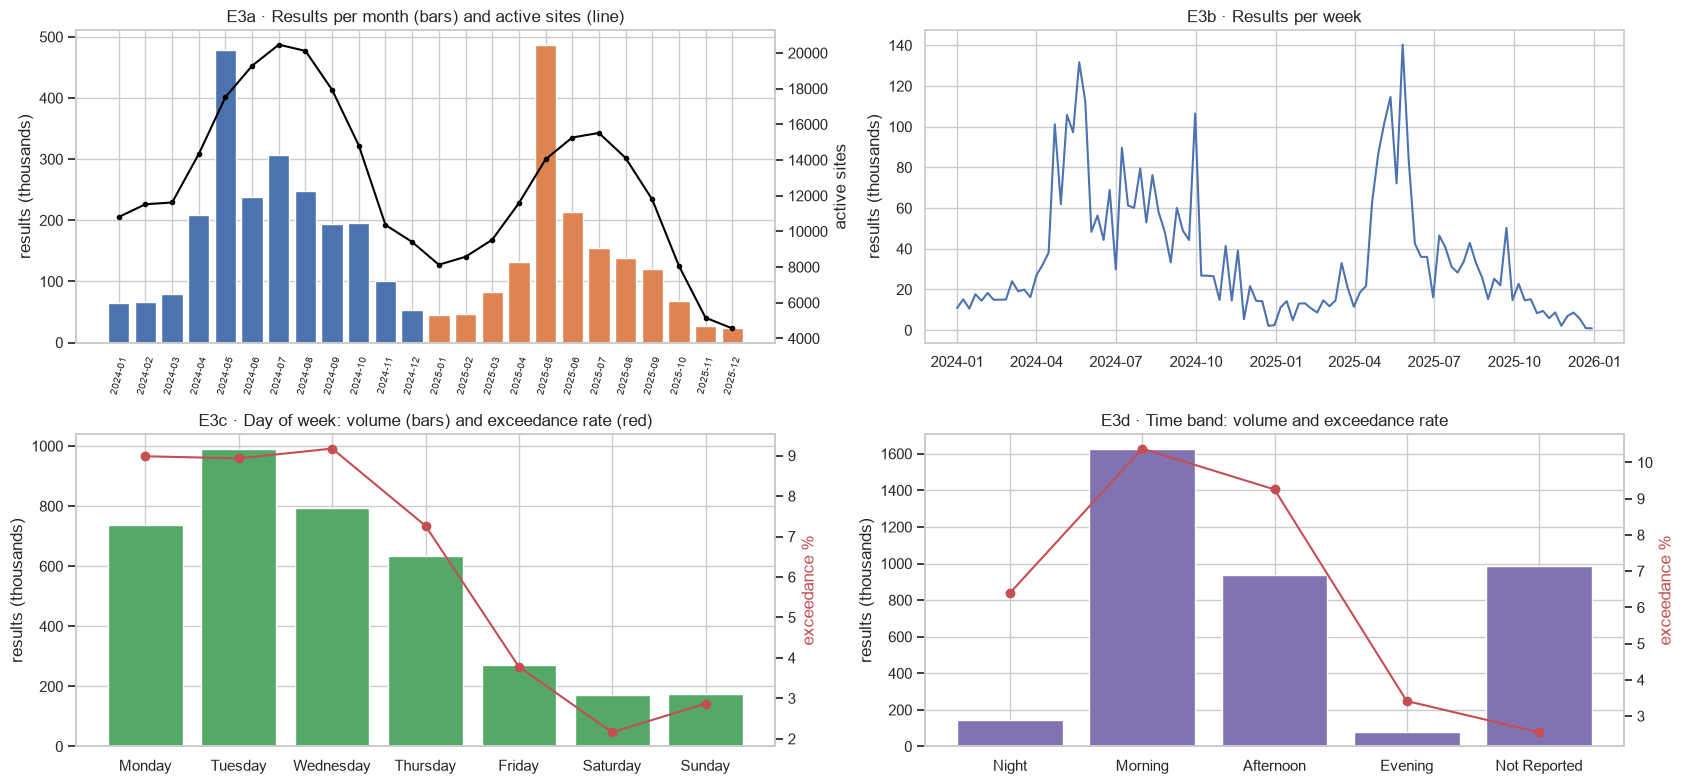

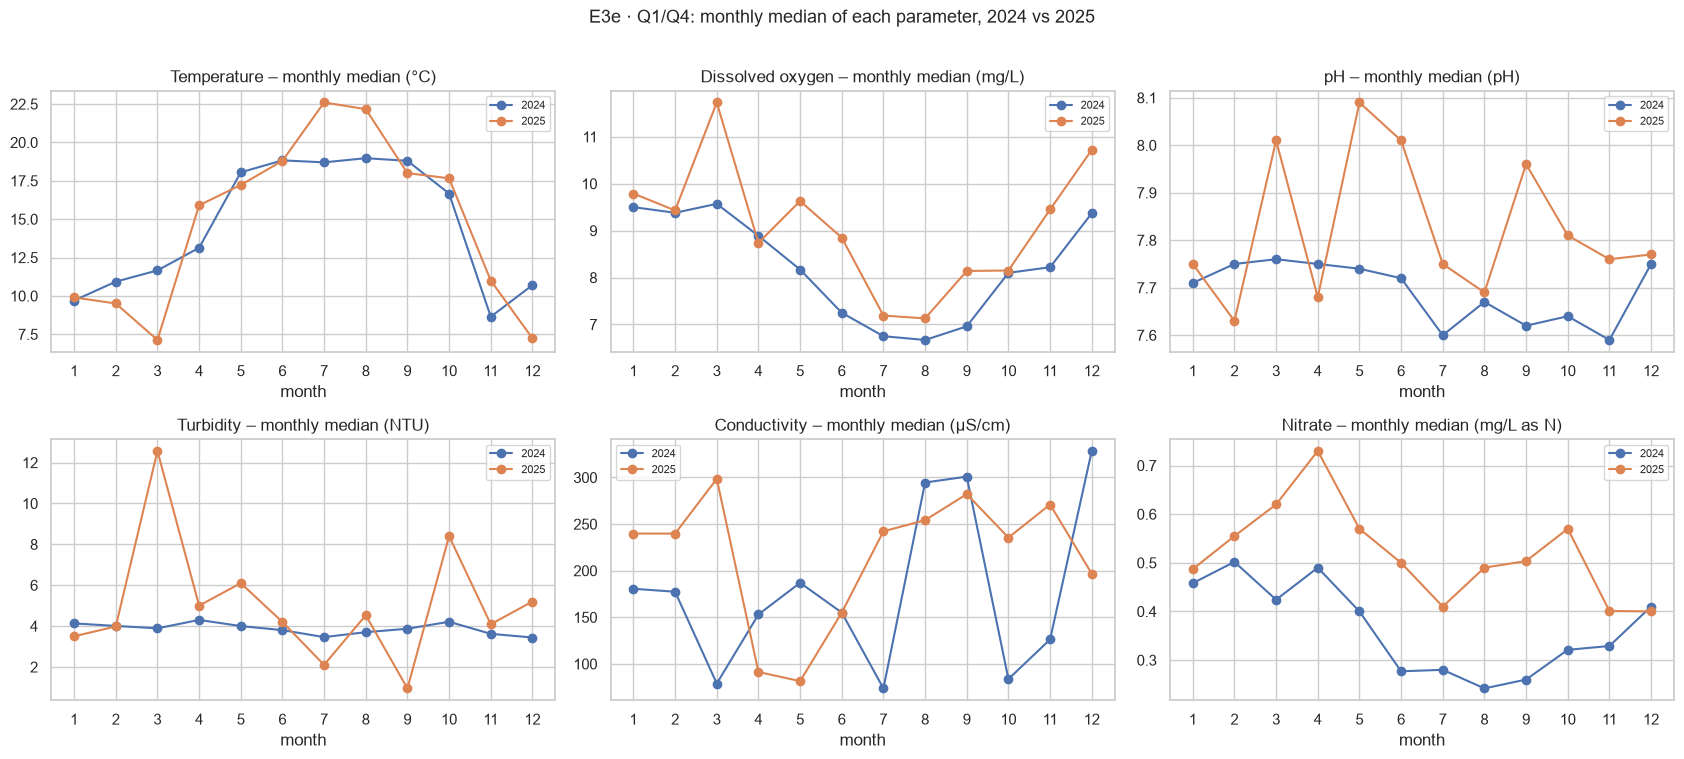

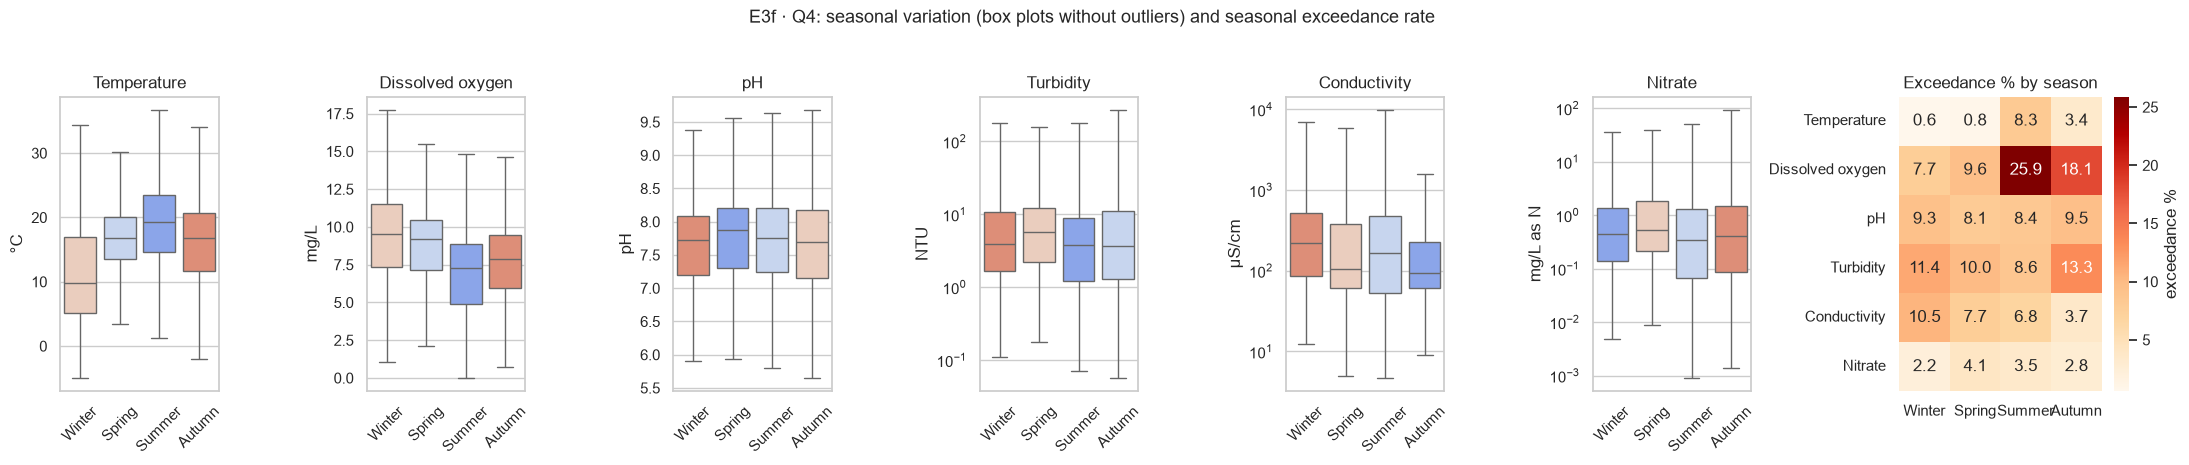

In [4]:
yr = q('SELECT year, count(*) results, count(DISTINCT site) sites, count(DISTINCT org) orgs, avg(exceedance_flag) * 100 exceed_rate FROM a GROUP BY 1 ORDER BY 1')
qt = q("SELECT year || '-Q' || quarter AS quarter, count(*) results, avg(exceedance_flag) * 100 exceed_rate FROM a GROUP BY 1 ORDER BY 1")
mo = q("SELECT strftime(dt, '%Y-%m') AS month, count(*) results, count(DISTINCT site) sites, avg(exceedance_flag) * 100 exceed_rate FROM a GROUP BY 1 ORDER BY 1")
wk = q("SELECT date_trunc('week', dt) AS week, count(*) results FROM a GROUP BY 1 ORDER BY 1")
dw = q("SELECT dayofweek(dt) AS d, day_of_week, count(*) results, avg(exceedance_flag) * 100 exceed_rate FROM a GROUP BY ALL ORDER BY d")
tbd = q("SELECT time_band, count(*) results, avg(exceedance_flag) * 100 exceed_rate FROM a GROUP BY 1 ORDER BY results DESC")
for n_, d in [('03_yearly', yr), ('03_quarterly', qt), ('03_monthly', mo), ('03_weekly', wk), ('03_day_of_week', dw), ('03_time_band', tbd)]: save_tab(d.round(3), n_)
display(yr.round(2)); display(qt.round(2))
peak, low = mo.loc[mo.results.idxmax()], mo.loc[mo.results.idxmin()]
print(f'Peak month: {peak.month} ({peak.results:,} results) · lowest month: {low.month} ({low.results:,} results)')

fig, axes = plt.subplots(2, 2, figsize=(17, 8))
ax = axes[0, 0]; ax.bar(mo.month, mo.results / 1e3, color=['#4C72B0' if m < '2025' else '#DD8452' for m in mo.month])
ax2 = ax.twinx(); ax2.plot(mo.month, mo.sites, color='black', marker='.', label='active sites'); ax2.set_ylabel('active sites'); ax2.grid(False)
ax.set(title='E3a · Results per month (bars) and active sites (line)', ylabel='results (thousands)'); ax.tick_params(axis='x', rotation=75, labelsize=7.5)
axes[0, 1].plot(wk.week, wk.results / 1e3, color='#4C72B0'); axes[0, 1].set(title='E3b · Results per week', ylabel='results (thousands)')
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dw2 = dw.set_index('day_of_week').loc[order]
axes[1, 0].bar(dw2.index, dw2.results / 1e3, color='#55A868'); a3 = axes[1, 0].twinx(); a3.plot(dw2.index, dw2.exceed_rate, color='#C44E52', marker='o'); a3.grid(False)
a3.set_ylabel('exceedance %', color='#C44E52'); axes[1, 0].set(title='E3c · Day of week: volume (bars) and exceedance rate (red)', ylabel='results (thousands)')
tb2 = tbd.set_index('time_band').reindex(['Night', 'Morning', 'Afternoon', 'Evening', 'Whole day', 'Not Reported']).dropna()
axes[1, 1].bar(tb2.index, tb2.results / 1e3, color='#8172B2'); a4 = axes[1, 1].twinx(); a4.plot(tb2.index, tb2.exceed_rate, color='#C44E52', marker='o'); a4.grid(False)
a4.set_ylabel('exceedance %', color='#C44E52'); axes[1, 1].set(title='E3d · Time band: volume and exceedance rate', ylabel='results (thousands)')
save_fig('03_temporal_volume')

mp = q("SELECT param, strftime(dt, '%Y-%m') AS month, median(value_std) med, count(*) n FROM a GROUP BY ALL ORDER BY month")
save_tab(mp.round(3), '03_monthly_parameter_median')
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, p in zip(axes.flat, PARAMS):
    d = mp[mp.param == p]; d = d.assign(yr=d.month.str[:4], m=d.month.str[5:].astype(int))
    for y, c in [('2024', '#4C72B0'), ('2025', '#DD8452')]:
        dd = d[d.yr == y]; ax.plot(dd.m, dd.med, marker='o', color=c, label=y)
    ax.set(title=f'{SHORT[p]} – monthly median ({UNIT[p]})', xticks=range(1, 13), xlabel='month'); ax.legend(fontsize=8)
fig.suptitle('E3e · Q1/Q4: monthly median of each parameter, 2024 vs 2025', y=1.01, fontsize=13)
save_fig('03_monthly_parameter_trend')

ss = q("SELECT param, season, median(value_std) med, avg(exceedance_flag) * 100 exc, count(*) n FROM a GROUP BY ALL")
so = ['Winter', 'Spring', 'Summer', 'Autumn']
sm = ss.pivot(index='param', columns='season', values='med').loc[PARAMS, so].rename(index=SHORT)
se = ss.pivot(index='param', columns='season', values='exc').loc[PARAMS, so].rename(index=SHORT)
save_tab(sm.round(3), '03_seasonal_median', index=True); save_tab(se.round(2), '03_seasonal_exceedance', index=True)
sbox = q("SELECT param, season, value_std FROM (SELECT param, season, value_std FROM a) USING SAMPLE reservoir(400000 ROWS) REPEATABLE (5)")
fig, axes = plt.subplots(1, 7, figsize=(22, 4.5), gridspec_kw={'width_ratios': [1] * 6 + [1.6]})
for ax, p in zip(axes[:6], PARAMS):
    d = sbox[sbox.param == p]
    if p in LOGP: d = d[d.value_std > 0]; ax.set_yscale('log')
    sns.boxplot(data=d, x='season', y='value_std', order=so, ax=ax, showfliers=False, palette='coolwarm', hue='season', legend=False)
    ax.set(title=SHORT[p], xlabel='', ylabel=UNIT[p]); ax.tick_params(axis='x', rotation=45)
sns.heatmap(se, annot=True, fmt='.1f', cmap='OrRd', ax=axes[6], cbar_kws={'label': 'exceedance %'}); axes[6].set(title='Exceedance % by season', xlabel='', ylabel='')
fig.suptitle('E3f · Q4: seasonal variation (box plots without outliers) and seasonal exceedance rate', y=1.03, fontsize=13)
save_fig('03_seasonal')

**Why these charts:** monthly bars with an active-site line separate *more sampling* from *more sites*. Weekly and day-of-week plots show the sampling rhythm, and the red lines put the outcome *rate* next to the volume. The 2024-vs-2025 lines test whether seasonal patterns repeat, and the seasonal box plots and heat map show the actual water-quality change by season.

**🔎 Inference (E3): temporal analysis (Q1, Q4)**
- **Q1, volume over time:**
  - 2024 has **2.23M** results (39,330 sites) and 2025 has **1.54M** (30,512 sites).
  - **Peak month: May 2025 (486,189)**; May 2024 is almost equal (478,712). **Lowest: December 2025 (23,189).**
  - Quarter 2 is the busiest every year. The **late-2025 drop** (Q4 2025: 117K vs 350K in Q4 2024) reflects **data not yet uploaded to WQP**, not less monitoring, so 2024-vs-2025 totals must not be compared as a trend.
- **Sampling rhythm:**
  - **Monday–Wednesday carry the most results**, and weekends are low (Saturday 170K vs Tuesday 989K): field crews work weekdays.
  - Weekend exceedance rates are lower (2–3%), because weekend data is mostly continuous loggers in healthier waters.
  - **Morning (43%)** is the main sampling time.
- **Q4, seasons (medians):**
  - **Temperature** rises from 9.8 °C (winter) to **19.3 °C (summer)**.
  - **Dissolved oxygen falls** from 9.7 to **7.3 mg/L** in summer, exactly what physics predicts: warm water holds less oxygen.
  - **The DO exceedance rate jumps to 25.9% in summer** (vs 7.7% in winter), and temperature exceedance to 8.3%.
  - **Turbidity** is highest in spring (5.8 NTU, snowmelt and rain runoff); its exceedance peaks in autumn (13.3%).
  - **Nitrate** is higher in winter–spring (0.46–0.50) than summer (0.32): plants and algae take up nitrate in the growing season, and spring runoff carries fertiliser.
  - **Conductivity** is highest in winter (217 µS/cm), possibly road salt and low flow.
- **2024 vs 2025 (E3e):** the **same seasonal shape repeats in both years** for temperature and DO, so the pattern is real, not a one-year accident. Month-to-month jumps in 2025 pH, turbidity and conductivity come from **fewer sites being sampled** (a changing site mix), not a real change in water.
- **Quarterly exceedance:** Q3 (summer) is worst both years (12.9% and 13.7%).
- **Impact:**
  - Seasonal comparisons must use **rates and medians** (sampling volume varies 20× across months).
  - **Season and month are strong predictors** for the models, especially for DO.
  - The real-time dashboard should expect **summer DO alerts**.

## 4 · Geographic and entity analysis (brief §5D) · answers **Q2** (compare sites), **Q3** (worst sites), **Q7** (coverage), **Q8** (location types)
**Fairness rule:** a site needs **at least 30 analysis-ready results for a parameter** before it is ranked. Without this, a site with 2 samples could top a "worst sites" list by chance.

,sites (≥30 results),P10 of site medians,median of site medians,P90 of site medians,lowest site median,highest site median
param,,,,,,
Temperature,5281.0,11.029,18.983,25.985,1.150,32.190
Dissolved oxygen,4237.0,4.300,7.410,9.810,0.000,14.850
pH,4070.0,6.865,7.770,8.320,4.300,10.370
Turbidity,1371.0,0.530,3.800,16.610,0.000,4761.174
Conductivity,447.0,40.400,256.205,2525.740,0.331,103100.000
Nitrate,338.0,0.003,0.336,2.893,0.000,10.000


,param,site,state,org,n,med,exc_rate,hr_rate
1767,Conductivity,21GAEPD_WQX-SH_07_15209,Georgia,21GAEPD_WQX,182,47267.95,100.00,100.00
2229,Conductivity,21GAEPD_WQX-SH_07_3049,Georgia,21GAEPD_WQX,147,52984.20,100.00,100.00
15522,Conductivity,21GAEPD_WQX-SH_02_15212,Georgia,21GAEPD_WQX,138,42299.75,100.00,100.00
14093,Conductivity,21GAEPD_WQX-SH_02_364,Georgia,21GAEPD_WQX,121,42728.60,100.00,100.00
9918,Conductivity,21GAEPD_WQX-SH_02_56,Georgia,21GAEPD_WQX,117,45453.50,100.00,100.00
2251,Dissolved oxygen,21FLDADE_WQX-LR05,Florida,21FLDADE_WQX,51,2.48,100.00,29.41
2960,Dissolved oxygen,21FLDADE_WQX-SP08,Florida,21FLDADE_WQX,51,0.77,100.00,94.12
4139,Dissolved oxygen,21FLDADE_WQX-TM06,Florida,21FLDADE_WQX,51,0.79,100.00,96.08
6361,Dissolved oxygen,21FLDADE_WQX-LR08,Florida,21FLDADE_WQX,51,2.82,100.00,35.29
8496,Dissolved oxygen,21FLDADE_WQX-WC03,Florida,21FLDADE_WQX,51,1.80,100.00,60.78


,sites,poor_sites,% poor (≥50% exceed)
param,,,
Temperature,5281,113,2.1
Dissolved oxygen,4237,592,14.0
pH,4070,186,4.6
Turbidity,1371,68,5.0
Conductivity,447,57,12.8
Nitrate,338,0,0.0


,org,results,sites,params,months,states,exc_rate
0,WIDNR_WQX,1298226,2330,4,24,4,1.89
1,MNPCA,273412,4108,5,24,5,11.87
2,WSG,221828,26,1,6,1,1.25
3,CTUIR_WQX,118462,35,5,10,2,4.07
4,21VASWCB,113075,1911,5,24,6,11.05
5,21AWIC,111722,577,4,24,5,18.47
6,21GAEPD_WQX,88210,461,5,24,4,19.95
7,UTAHDWQ_WQX,65875,777,4,24,5,5.03
8,11NPSWRD_WQX,56947,562,6,24,26,4.13
9,21NC03WQ,56282,533,4,24,4,15.10


,Value
Organizations,468.0
Orgs covering all 24 months,55.0
Orgs measuring all 6 parameters,33.0
Median sites per org,20.0
Share of results from top 10 orgs (%),63.7


param,Temperature,Dissolved oxygen,pH,Turbidity,Conductivity,Nitrate
water_type,,,,,,
Groundwater,22.50,0.57,7.22,0.86,639.0,2.40
Ocean Water,11.00,10.75,8.11,1.87,41825.0,NaN
Surface Water,20.39,7.09,7.64,3.06,189.0,0.36


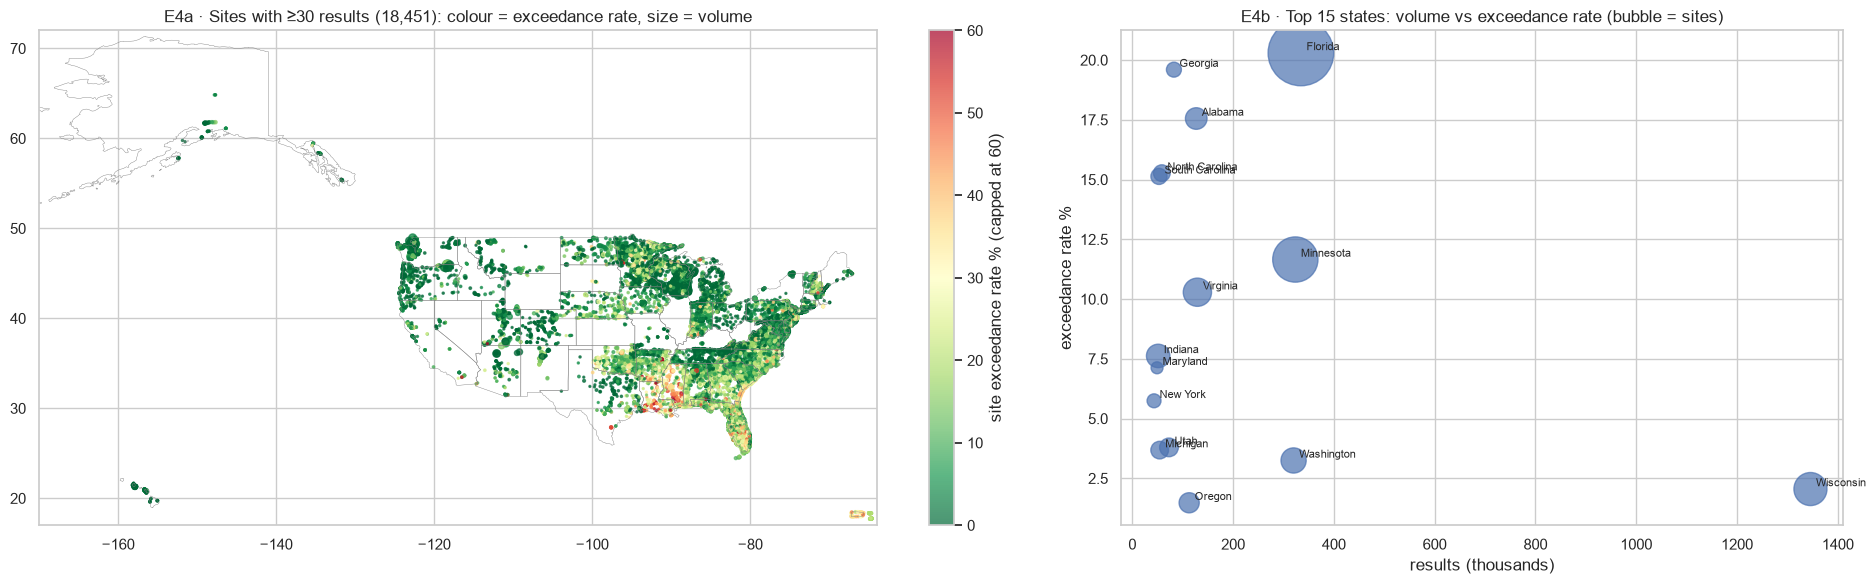

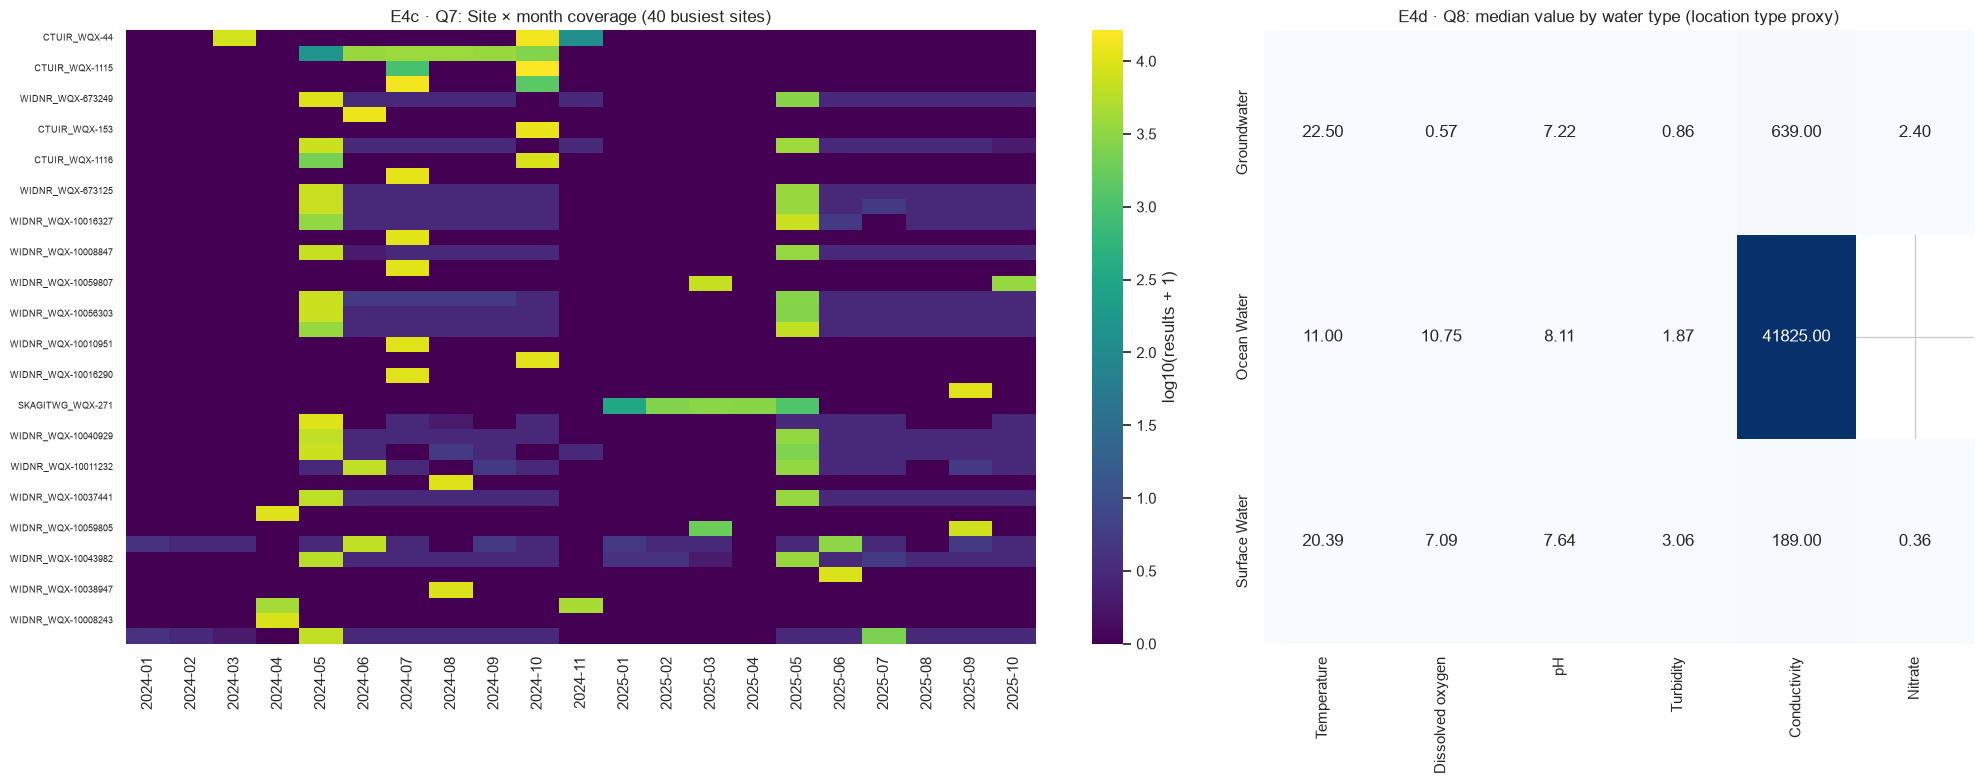

In [5]:
MINN = 30
sm_ = q(f'''SELECT site, param, any_value(state) state, any_value(region) region, any_value(org) org, count(*) n, median(value_std) med,
                   avg(exceedance_flag) * 100 exc_rate, sum(exceedance_flag) exc_n, avg(high_risk_flag) * 100 hr_rate
            FROM a GROUP BY site, param HAVING count(*) >= {MINN}''')
save_tab(sm_.round(3), '04_site_parameter_stats')
spread = sm_.groupby('param').med.describe(percentiles=[0.1, 0.5, 0.9])[['count', '10%', '50%', '90%', 'min', 'max']].loc[PARAMS].rename(index=SHORT)
spread.columns = ['sites (≥30 results)', 'P10 of site medians', 'median of site medians', 'P90 of site medians', 'lowest site median', 'highest site median']
display(save_tab(spread.round(3), '04_Q2_site_median_spread', index=True))
worst = (sm_.sort_values(['param', 'exc_rate', 'n'], ascending=[True, False, False]).groupby('param').head(5))
worst = worst[worst.exc_rate > 0][['param', 'site', 'state', 'org', 'n', 'med', 'exc_rate', 'hr_rate']]
worst['param'] = worst.param.map(SHORT); display(save_tab(worst.round(2), '04_Q3_worst_sites'))
poor = sm_.assign(poor=sm_.exc_rate >= 50).groupby('param').agg(sites=('site', 'count'), poor_sites=('poor', 'sum')).loc[PARAMS].rename(index=SHORT)
poor['% poor (≥50% exceed)'] = (poor.poor_sites / poor.sites * 100).round(1); display(save_tab(poor, '04_Q3_poor_sites', index=True))

stt = q('''SELECT state, region, count(*) results, count(DISTINCT site) sites, count(DISTINCT org) orgs, avg(exceedance_flag) * 100 exc_rate,
                  sum(exceedance_flag) exc_n FROM a WHERE state NOT IN ('Unknown') GROUP BY ALL ORDER BY results DESC''')
save_tab(stt.round(2), '04_state_summary')
orgc = q('''SELECT org, count(*) results, count(DISTINCT site) sites, count(DISTINCT param) params, count(DISTINCT strftime(dt, '%Y-%m')) AS months,
                   count(DISTINCT state) states, avg(exceedance_flag) * 100 exc_rate FROM a GROUP BY org ORDER BY results DESC''')
display(save_tab(orgc.head(15).round(2), '04_Q7_org_coverage'))
covq = pd.DataFrame({'Value': {'Organizations': len(orgc), 'Orgs covering all 24 months': int((orgc.months == 24).sum()),
       'Orgs measuring all 6 parameters': int((orgc.params == 6).sum()), 'Median sites per org': orgc.sites.median(),
       'Share of results from top 10 orgs (%)': round(orgc.results.head(10).sum() / orgc.results.sum() * 100, 1)}})
display(save_tab(covq, '04_Q7_coverage_summary', index=True))
wtq = q('''SELECT water_type, param, count(*) n, median(value_std) med, avg(exceedance_flag) * 100 exc FROM a
           WHERE water_type IN ('Surface Water', 'Groundwater', 'Ocean Water') GROUP BY ALL''')
wtm = wtq.pivot(index='water_type', columns='param', values='med')[PARAMS].rename(columns=SHORT)
wtn = wtq.pivot(index='water_type', columns='param', values='n')[PARAMS].rename(columns=SHORT)
display(save_tab(wtm.round(2), '04_Q8_watertype_median', index=True)); save_tab(wtn, '04_Q8_watertype_counts', index=True)

sites_map = q('''SELECT site, median(lat) lat, median(lon) lon, count(*) n, avg(exceedance_flag) * 100 exc FROM a
                 WHERE lat IS NOT NULL GROUP BY site HAVING count(*) >= 30''')
gj = json.load(open(ROOT / 'data' / 'reference' / 'us-states.json'))
fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={'width_ratios': [1.45, 1]})
for f in gj['features']:
    g = f['geometry']; rings = [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']
    for poly in rings: r_ = np.array(poly[0]); axes[0].plot(r_[:, 0], r_[:, 1], color='grey', lw=0.3)
sc = axes[0].scatter(sites_map.lon, sites_map.lat, c=sites_map.exc.clip(upper=60), s=np.clip(np.sqrt(sites_map.n) / 3, 2, 30), cmap='RdYlGn_r', alpha=0.7)
plt.colorbar(sc, ax=axes[0], label='site exceedance rate % (capped at 60)')
axes[0].set(xlim=(-170, -64), ylim=(17, 72), title=f'E4a · Sites with ≥30 results ({len(sites_map):,}): colour = exceedance rate, size = volume')
t15 = stt.head(15)
axes[1].scatter(t15.results / 1e3, t15.exc_rate, s=t15.sites / 5 + 20, color='#4C72B0', alpha=0.7)
for _, r_ in t15.iterrows(): axes[1].annotate(r_.state, (r_.results / 1e3, r_.exc_rate), fontsize=8, xytext=(4, 2), textcoords='offset points')
axes[1].set(title='E4b · Top 15 states: volume vs exceedance rate (bubble = sites)', xlabel='results (thousands)', ylabel='exceedance rate %')
save_fig('04_geography')

top_sites = q('SELECT site FROM a GROUP BY site ORDER BY count(*) DESC LIMIT 40').site
hm = q(f'''SELECT site, strftime(dt, '%Y-%m') m, count(*) n FROM a WHERE site IN ({', '.join(repr(s) for s in top_sites)}) GROUP BY ALL''')
hmp = hm.pivot(index='site', columns='m', values='n').reindex(top_sites).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(np.log10(hmp + 1), cmap='viridis', ax=axes[0], cbar_kws={'label': 'log10(results + 1)'})
axes[0].set(title='E4c · Q7: Site × month coverage (40 busiest sites)', xlabel='', ylabel=''); axes[0].tick_params(axis='y', labelsize=6.5)
wtm_n = (wtm / wtm.loc['Surface Water'])
sns.heatmap(wtm, annot=True, fmt='.2f', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set(title='E4d · Q8: median value by water type (location type proxy)', xlabel='', ylabel='')
save_fig('04_coverage_watertype')

**Why these charts:** the map shows *where* problems concentrate (colour) and where monitoring is intense (size). The volume-vs-rate bubble chart separates "measured a lot" from "often bad". The site × month heat map exposes gaps in coverage, and the water-type table compares location types (the closest available proxy for the brief's *MonitoringLocationTypeName*).

**🔎 Inference (E4): sites, states, organizations (Q2, Q3, Q7, Q8)**
- **Q2, comparing sites (≥ 30 results each):** site medians spread widely.
  - Temperature: P10–P90 **11.0–26.0 °C**.
  - DO: **4.3–9.8 mg/L**.
  - pH: **6.9–8.3**.
  - Turbidity: **0.5–16.6 NTU**.
  - Conductivity: **40–2,526 µS/cm**.
  - Nitrate: **0.003–2.9 mg/L**.
  - Site *location* explains a lot of the variation, so **site/state is an important model feature**.
- **Q3, worst sites (fair ranking with ≥ 30 results):**
  - **Conductivity:** Georgia coastal sites (21GAEPD, median ~42,000–53,000 µS/cm). These are **estuaries**, salty by nature.
  - **DO:** Miami-Dade, Florida sites (21FLDADE) at **100% exceedance**, some with median DO below 1 mg/L.
  - **pH:** Alabama (21AWIC) and Virginia sites with **acidic** water (median pH 5.1–5.9).
  - **Turbidity:** Arkansas and Minnesota sites with medians around 100 NTU.
  - **Temperature:** Gulf-coast sites (Mississippi, Alabama, Florida, Puerto Rico).
  - **Nitrate:** Iowa and Minnesota farm-belt sites (up to 28% exceedance).
  - **"Poor" sites (≥ 50% exceedance):** **14% of DO sites** and 12.8% of conductivity sites, but **0% of nitrate sites**.
- **Map (E4a):** problem sites cluster along the **Gulf Coast and Florida** (warm, low-oxygen water), while the northern states, Pacific Northwest and Alaska are mostly green.
- **Volume ≠ rate (E4b):**
  - **Wisconsin** has the most results (1.35M) but one of the **lowest exceedance rates (2.1%)**.
  - **Florida** has the most sites (11,059) and **the highest rate (20.3%)**; Georgia (19.6%) and Alabama (17.6%) follow.
- **Q7, coverage:**
  - 468 organizations; **the top 10 supply 63.7% of all results**.
  - Only **55 organizations cover all 24 months** and only **33 measure all six parameters**; the median organization monitors 20 sites.
  - The site × month heat map (E4c) shows the busiest sites are **monitored continuously**, while many others have seasonal gaps (winter).
- **Q8, location types (proxy: water type):**
  - **Groundwater** is warmer (22.5 °C), **very low in oxygen (0.57 mg/L)**, clearer (0.86 NTU) and **higher in nitrate (2.4 mg/L)** than surface water (DO 7.1, nitrate 0.36).
  - **Ocean water** is cold, oxygen-rich (10.8 mg/L) and salty (41,825 µS/cm).
  - Location type therefore changes what "normal" means, so thresholds should ideally be **location-type-specific** (a recommendation for later).

## 5 · Outcome analysis (brief §5E) · answers **Q6** (exceedance / high-risk observations)
**What:** exceedances and high-risk results by parameter, shown as both **counts** and **rates**, and organizations compared by volume vs rate.
**Why:** the brief requires separating *high volume* from *high rate*. A parameter or organization can have the most exceedances simply because it measures the most. **No causal claims** are made here, only patterns.

,results,exceedances,exc_rate,high_risk,hr_rate,sites_with_exc
param,,,,,,
Temperature,1912387,64652.0,3.381,4308.0,0.225,10776
Dissolved oxygen,690164,125770.0,18.223,59111.0,8.565,14636
pH,658268,57404.0,8.720,19680.0,2.990,9393
Turbidity,336418,35339.0,10.504,8353.0,2.483,6523
Conductivity,131417,7985.0,6.076,5858.0,4.458,784
Nitrate,43379,1421.0,3.276,442.0,1.019,380


,org,results,sites,params,months,states,exc_rate,exceedances
1,MNPCA,273412,4108,5,24,5,11.87,32455.0
0,WIDNR_WQX,1298226,2330,4,24,4,1.89,24575.0
5,21AWIC,111722,577,4,24,5,18.47,20636.0
6,21GAEPD_WQX,88210,461,5,24,4,19.95,17596.0
4,21VASWCB,113075,1911,5,24,6,11.05,12498.0
14,21MSWQ_WQX,37481,327,5,24,5,28.91,10834.0
13,21FLSFWM_WQX,38015,538,4,20,1,25.90,9847.0
9,21NC03WQ,56282,533,4,24,4,15.10,8500.0
16,21FLHILL_WQX,30669,261,4,19,1,20.63,6326.0
20,21FLDADE_WQX,23093,139,4,17,1,23.82,5500.0


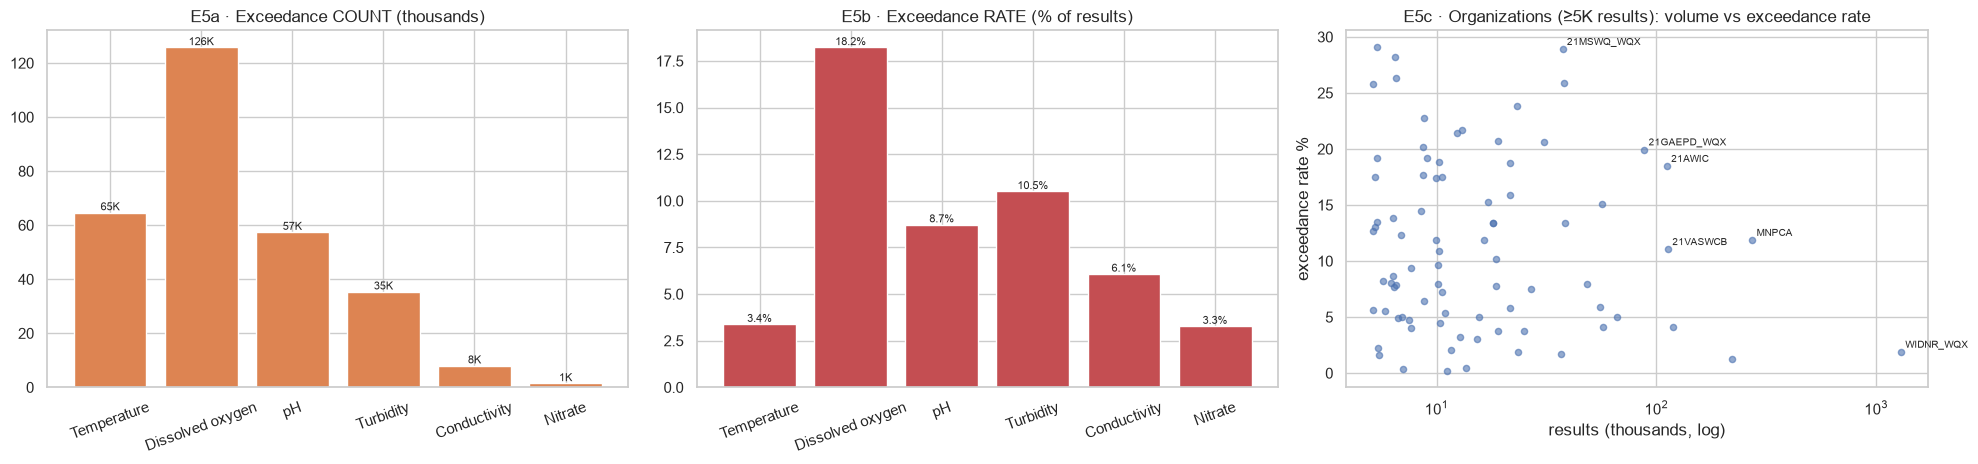

In [6]:
oc = q('''SELECT param, count(*) results, sum(exceedance_flag) exceedances, avg(exceedance_flag) * 100 exc_rate,
                 sum(high_risk_flag) high_risk, avg(high_risk_flag) * 100 hr_rate, count(DISTINCT site) FILTER (WHERE exceedance_flag = 1) sites_with_exc
          FROM a GROUP BY param''').set_index('param').loc[PARAMS].rename(index=SHORT)
display(save_tab(oc.round(3), '05_Q6_exceedance_by_parameter', index=True))
og = orgc[orgc.results >= 5000].copy()
og['exceedances'] = (og.exc_rate / 100 * og.results).round()
display(save_tab(og.sort_values('exceedances', ascending=False).head(10).round(2), '05_org_volume_vs_rate'))
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
axes[0].bar(oc.index, oc.exceedances / 1e3, color='#DD8452'); axes[0].set(title='E5a · Exceedance COUNT (thousands)'); axes[0].tick_params(axis='x', rotation=20)
axes[1].bar(oc.index, oc.exc_rate, color='#C44E52'); axes[1].set(title='E5b · Exceedance RATE (% of results)'); axes[1].tick_params(axis='x', rotation=20)
for ax_, col in [(axes[0], 'exceedances'), (axes[1], 'exc_rate')]:
    for i, v_ in enumerate(oc[col]): ax_.text(i, (v_ / 1e3 if col == 'exceedances' else v_), f'{v_ / 1e3:.0f}K' if col == 'exceedances' else f'{v_:.1f}%', ha='center', va='bottom', fontsize=8)
axes[2].scatter(og.results / 1e3, og.exc_rate, s=20, alpha=0.6, color='#4C72B0'); axes[2].set_xscale('log')
for _, r_ in og.sort_values('exceedances', ascending=False).head(6).iterrows():
    axes[2].annotate(r_.org, (r_.results / 1e3, r_.exc_rate), fontsize=7.5, xytext=(3, 3), textcoords='offset points')
axes[2].set(title='E5c · Organizations (≥5K results): volume vs exceedance rate', xlabel='results (thousands, log)', ylabel='exceedance rate %')
save_fig('05_outcome_count_vs_rate')

**Why these charts:** the same exceedances shown twice, as a count and as a rate, make the volume-vs-rate difference obvious. The scatter places each organization by how much it measures and how often its results exceed thresholds.

**🔎 Inference (E5): outcome analysis, counts vs rates (Q6)**
- **292,571 exceedances (7.8%)** and **97,752 high-risk results (2.6%)** among 3.77M analysis-ready results.
- **By parameter:** DO is first by **both count (125,770) and rate (18.2%)**, with 59,111 high-risk results (DO < 2 mg/L) across **14,636 sites**.
- **Count vs rate tells different stories:**
  - **Temperature** has the 2nd-highest *count* (64,652) only because it is measured most (1.9M results); its *rate* is low (3.4%).
  - **Turbidity (10.5%) and pH (8.7%)** have higher rates than temperature despite fewer results.
  - **Nitrate** exceeds rarely (3.3%, 1,421 results at 380 sites).
- **Organizations (E5c):**
  - **MNPCA (Minnesota)** has the most exceedances (32,455) at a moderate rate (11.9%).
  - **WIDNR (Wisconsin)** is 2nd by count (24,575) but has the **lowest rate (1.9%)**: big volume, not big risk.
  - Smaller southern organizations (**21MSWQ 28.9%, 21FLSFWM 25.9%, 21FLDADE 23.8%**) have the **highest rates**.
- **No causal claim:** a high rate may reflect *where* an organization monitors (warm, coastal, problem waters), not worse water management. Organizations often target known problem sites.
- **Impact:** the dashboard must show **both counts and rates**, and rank sites/organizations by **rate with a minimum sample size**, as the brief requires.

## 6 · Relationships among parameters · answers **Q5**
**What:** correlation between parameters **measured at the same site on the same day** (co-located data, as the brief requires). For each site-day the median of each parameter is taken, and pairs are correlated.
- **Pearson** measures straight-line relationships.
- **Spearman** uses ranks, so it is robust to skew and outliers; it is preferred for turbidity, conductivity and nitrate.

**Why:** these relationships guide the regression model (Step 10). Physics says warmer water holds **less** oxygen, so a negative temperature–DO correlation is expected and confirms the data behaves sensibly.
**Caution:** correlation ≠ causation.

Site-days: 404,327


,Temperature,Dissolved oxygen,pH,Turbidity,Conductivity,Nitrate
Temperature,358331,285617,277440,173712,50326,26012
Dissolved oxygen,285617,300762,274845,170934,49729,24204
pH,277440,274845,298787,169787,51269,26307
Turbidity,173712,170934,169787,195566,34288,15109
Conductivity,50326,49729,51269,34288,54507,5620
Nitrate,26012,24204,26307,15109,5620,34241


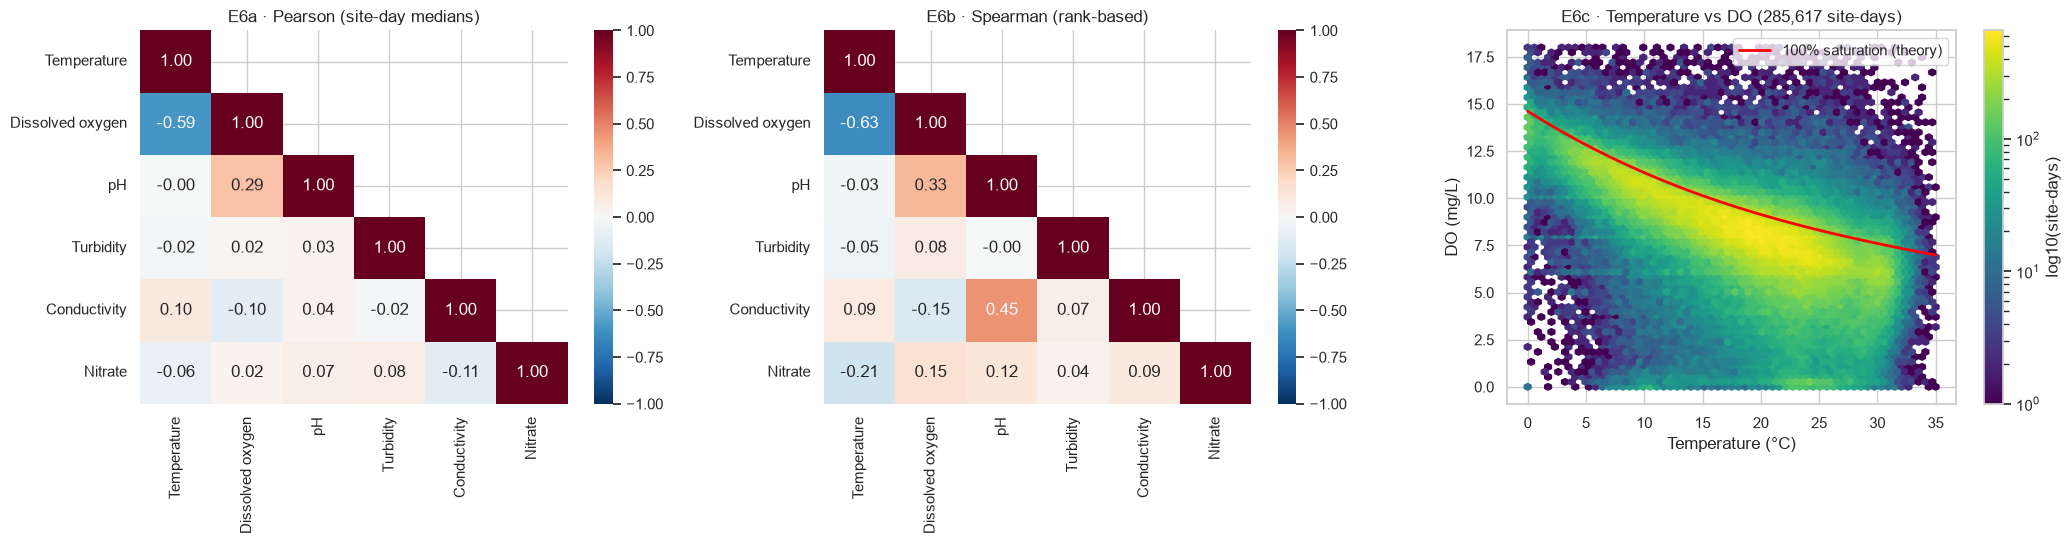

In [7]:
sd = q('''PIVOT (SELECT site, dt, param, median(value_std) v FROM a GROUP BY ALL) ON param USING first(v) GROUP BY site, dt''')
sd = sd.rename(columns=SHORT); cols = [SHORT[p] for p in PARAMS]
print(f'Site-days: {len(sd):,}')
pairs = pd.DataFrame(index=cols, columns=cols, dtype=float)
for i in cols:
    for j in cols: pairs.loc[i, j] = (sd[i].notna() & sd[j].notna()).sum()
save_tab(pairs.astype(int), '06_Q5_pair_counts', index=True); display(pairs.astype(int))
pear = sd[cols].corr(method='pearson', min_periods=200); spear = sd[cols].corr(method='spearman', min_periods=200)
save_tab(pear.round(3), '06_Q5_pearson', index=True); save_tab(spear.round(3), '06_Q5_spearman', index=True)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6), gridspec_kw={'width_ratios': [1, 1, 1.05]})
mask = np.triu(np.ones_like(pear, dtype=bool), 1)
sns.heatmap(pear, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0]); axes[0].set(title='E6a · Pearson (site-day medians)')
sns.heatmap(spear, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[1]); axes[1].set(title='E6b · Spearman (rank-based)')
td = sd[['Temperature', 'Dissolved oxygen']].dropna()
hb = axes[2].hexbin(td.Temperature, td['Dissolved oxygen'], gridsize=60, bins='log', cmap='viridis', extent=(0, 35, 0, 18))
plt.colorbar(hb, ax=axes[2], label='log10(site-days)')
tt = np.linspace(0, 35, 50); axes[2].plot(tt, 14.62 - 0.3898 * tt + 0.006969 * tt ** 2 - 0.00005897 * tt ** 3, color='red', lw=2, label='100% saturation (theory)')
axes[2].set(title=f'E6c · Temperature vs DO ({len(td):,} site-days)', xlabel='Temperature (°C)', ylabel='DO (mg/L)'); axes[2].legend()
save_fig('06_Q5_relationships')

**Why these charts:** two correlation heat maps (straight-line and rank-based) side by side show which relationships are robust. The hexbin plot shows the strongest pair in detail with a theoretical saturation curve, which checks the data against known physics.

**🔎 Inference (E6): relationships among parameters (Q5)**
- Based on **404,327 site-days** where parameters were measured together. The common pairs (temperature, DO and pH) have 275K–286K site-days each; nitrate pairs only 15K–26K.
- **Temperature vs DO: strong negative relationship (Spearman −0.63, Pearson −0.59).** Warmer water holds less oxygen. In the hexbin plot (E6c) most points sit **just below the theoretical 100%-saturation curve**, which confirms the cleaned data follows known physics (a strong validity check). Points far below the curve are **oxygen-depleted waters** (e.g. deep lake layers, polluted reaches).
- **pH vs DO: moderate positive (+0.33).** Photosynthesis by algae raises both oxygen and pH at the same time.
- **pH vs conductivity: moderate positive (Spearman +0.45, but Pearson only +0.04).** A monotonic but non-linear relationship: harder, mineral-rich water is both more alkaline and more conductive. The big gap between Spearman and Pearson shows why rank correlation is needed for skewed parameters.
- **Temperature vs nitrate: weak negative (−0.21).** This matches the seasonal pattern: less nitrate in warm months.
- **Turbidity is almost unrelated** to the other parameters (|r| ≤ 0.08). It is driven by rain events, not by water chemistry.
- **Impact for modelling (Step 10):**
  - **Temperature is the strongest predictor of DO**, with pH and conductivity as secondary predictors.
  - Turbidity adds little to predicting DO.
  - Use **Spearman/log transforms** for skewed parameters.
  - These are associations, not proof of cause.

## 7 · First answers to the mandatory business questions (EDA level)
Each answer is built from the tables above. The final answers come from the warehouse/OLAP (Step 9) and the models (Step 10).

In [8]:
ans = pd.DataFrame([
 ('Q1', 'Water-quality measurements over time', 'E3a, E3e', f"Peak month {peak.month} ({peak.results:,}); lowest {low.month} ({low.results:,}); see E3e for parameter trends"),
 ('Q2', 'Compare parameters across sites', 'E04_Q2 table', 'Spread of site medians (P10–P90) per parameter'),
 ('Q3', 'Sites with extreme / poor quality', 'E04_Q3 tables, E4a', f"Worst sites listed per parameter (≥{MINN} results); % of poor sites per parameter"),
 ('Q4', 'Seasonal variation', 'E3f', 'Seasonal medians and exceedance rates per parameter'),
 ('Q5', 'Relationships among pH, DO, turbidity, nutrients', 'E6', f"Temperature–DO Spearman = {spear.loc['Temperature', 'Dissolved oxygen']:.2f}"),
 ('Q6', 'Exceedance / high-risk observations', 'E5', f"Highest exceedance rate: {oc.exc_rate.idxmax()} ({oc.exc_rate.max():.1f}%); most exceedances by count: {oc.exceedances.idxmax()}"),
 ('Q7', 'Site and organization sampling coverage', 'E4c, E04_Q7', f"Top 10 orgs supply {covq.loc['Share of results from top 10 orgs (%)', 'Value']}% of results"),
 ('Q8', 'Compare monitoring-location types', 'E4d', 'Surface vs ground vs ocean water (proxy until the Station file adds site types)'),
], columns=['Q', 'Question', 'Evidence', 'EDA answer'])
display(save_tab(ans, '07_question_answers'))

,Q,Question,Evidence,EDA answer
0,Q1,Water-quality measurements over time,"E3a, E3e","Peak month 2025-05 (486,189); lowest 2025-12 (..."
1,Q2,Compare parameters across sites,E04_Q2 table,Spread of site medians (P10–P90) per parameter
2,Q3,Sites with extreme / poor quality,"E04_Q3 tables, E4a",Worst sites listed per parameter (≥30 results)...
3,Q4,Seasonal variation,E3f,Seasonal medians and exceedance rates per para...
4,Q5,"Relationships among pH, DO, turbidity, nutrients",E6,Temperature–DO Spearman = -0.63
5,Q6,Exceedance / high-risk observations,E5,Highest exceedance rate: Dissolved oxygen (18....
6,Q7,Site and organization sampling coverage,"E4c, E04_Q7",Top 10 orgs supply 63.7% of results
7,Q8,Compare monitoring-location types,E4d,Surface vs ground vs ocean water (proxy until ...


**🔎 Inference (E7): EDA answers to the mandatory questions**
| Q | Short answer from the data |
|---|---|
| Q1 | Monitoring peaks in May (≈480K results/month) and is lowest in December. Q2 is busiest; late 2025 is incomplete in WQP. |
| Q2 | Site medians vary widely (e.g. DO 4.3–9.8 mg/L between P10 and P90 sites), so location matters a lot. |
| Q3 | Worst: Georgia estuaries (conductivity), Miami-Dade sites (DO < 1–3 mg/L), Alabama/Virginia acidic streams (pH 5–6), Iowa/Minnesota farm sites (nitrate). 14% of DO sites are "poor". |
| Q4 | Summer: temperature ↑ (19.3 °C), DO ↓ (7.3 mg/L), DO exceedance 25.9% vs 7.7% in winter. The pattern repeats in 2024 and 2025. |
| Q5 | Temperature–DO −0.63 (physics confirmed); pH–DO +0.33; pH–conductivity +0.45; turbidity independent. |
| Q6 | 292,571 exceedances (7.8%), 97,752 high-risk. DO is highest by count and rate (18.2%). |
| Q7 | 468 organizations, the top 10 = 63.7% of results; only 55 cover all 24 months and 33 measure all 6 parameters. |
| Q8 | Groundwater: very low DO (0.57) and higher nitrate (2.4); ocean: salty (41,825 µS/cm). Location type changes what is "normal". |

These EDA answers are confirmed with warehouse OLAP queries (Step 9). Q9–Q10 are answered by the mining models (Step 10).

## Outputs
- `02_eda/figures/E*.png`: charts for the report and PPT
- `02_eda/tables/E*.csv`: evidence tables
- **Next:** Step 4, feature selection (`03_feature_selection/`)